In [67]:
from os.path import join, dirname
import os
import sys
import gc
import logging
import argparse
from copy import deepcopy
import numpy as np
import torchshow as ts
import torchvision
from einops import rearrange
from matplotlib import pyplot as plt

import torch
from torch import autocast
from torch.cuda.amp import GradScaler
import torch.nn.functional as F
import torch.distributed as dist
import torch.multiprocessing as mp

sys.path.append(join(dirname(dirname(os.getcwd()))))
sys.path.append(os.getcwd())

from memoryPerceiver.memory_perceiver.main.configuration import cf
from memoryPerceiver.memory_perceiver.core.model_wrapper import create_memories, reset_memories
from memoryPerceiver.memory_perceiver.core.distributed import setup_distributed, average_gradients, scatter_dummy_src, gather_dummy_src
from memoryPerceiver.memory_perceiver.core.miscellaneous import custom_random, print_cuda_tensors
import memoryPerceiver.memory_perceiver.isaac.trainer as tr
from memoryPerceiver.memory_perceiver.isaac.plot import Plotter
from memoryPerceiver.memory_perceiver.isaac.agent import ActorCritic, ActorCriticSimple, ActorCriticPerceiver, create_agent

from memoryPerceiver.memory_perceiver.core.model_net import PerceiverIO
from memoryPerceiver.memory_perceiver.core.model_wrapper import create_multimodal_perceiver, output_projection, input_embedding
from memoryPerceiver.memory_perceiver.core.sequential_mnist import MnistDataset
from memoryPerceiver.memory_perceiver.core.torch_uoro import UOROModel

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [28]:
!wget www.di.ens.fr/~lelarge/MNIST.tar.gz
!tar -zxvf MNIST.tar.gz

--2024-09-14 08:47:49--  http://www.di.ens.fr/~lelarge/MNIST.tar.gz
Resolving www.di.ens.fr (www.di.ens.fr)... 129.199.99.14
Connecting to www.di.ens.fr (www.di.ens.fr)|129.199.99.14|:80... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://www.di.ens.fr/~lelarge/MNIST.tar.gz [following]
--2024-09-14 08:47:49--  https://www.di.ens.fr/~lelarge/MNIST.tar.gz
Connecting to www.di.ens.fr (www.di.ens.fr)|129.199.99.14|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified [application/x-gzip]
Saving to: ‘MNIST.tar.gz.1’

MNIST.tar.gz.1          [          <=>       ]  33.20M  16.3MB/s    in 2.0s    

2024-09-14 08:47:51 (16.3 MB/s) - ‘MNIST.tar.gz.1’ saved [34813078]

MNIST/
MNIST/raw/
MNIST/raw/train-labels-idx1-ubyte
MNIST/raw/t10k-labels-idx1-ubyte.gz
MNIST/raw/t10k-labels-idx1-ubyte
MNIST/raw/t10k-images-idx3-ubyte.gz
MNIST/raw/train-images-idx3-ubyte
MNIST/raw/train-labels-idx1-ubyte.gz
MNIST/raw/t10k-images-idx3-ubyte
MNIST/raw

In [68]:
# training
iter_id = 0
sum_acc = 0
sum_loss = 0
sum_trn_loss = 0
count = 0
update_count = 0

pred_series = []
losses = []
device='cpu'
model=UOROModel(28, 256, 10, 1e-3, device)
model.initialize_state()
mnist_dataset=MnistDataset(dataset_folder='./data')

In [69]:
loss_all=[]

In [70]:
X, Y = mnist_dataset.get_image(6000)

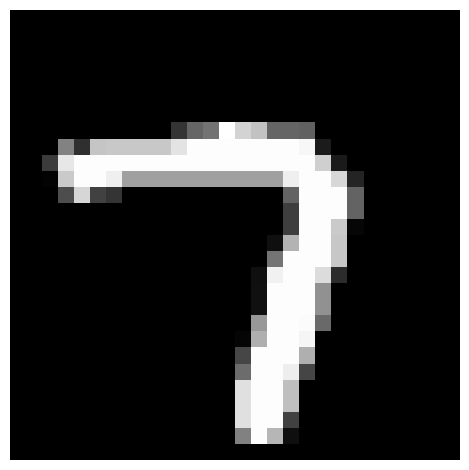

In [71]:
ts.show(X[:,0])

In [72]:
loss_acc=0
iter_id=0
while iter_id < 10000:
    if iter_id % 28 == 0:
        model.initialize_state()
        X, Y = mnist_dataset.get_image(iter_id)
        loss, acc = model.predict_mnist(x_t, y_t)

        sum_acc += acc
        sum_loss += loss
        count += 14

        x_t, y_t = mnist_dataset[iter_id]
        print(loss_acc/28)
        loss_all.append(loss_acc/28)
        loss_acc=0
        
    loss, acc, state_old, state_new = model.forward(x_t, y_t)
    loss_acc += loss
    
    iter_id += 1

0.0


0.09149896795549596
0.4461989724742515
0.5695285263271737
0.5667135347612202
0.6034794902162892
0.6095084478147328
0.3210463466654931
0.8694400265147644
0.29602658855063574
0.4329363581325327
0.5916357393642622
0.6074095363063472
0.4500185108876654
1.3657917865285916
0.3974051627197436
1.5311768963666899
0.545756211171725
1.4637406864868743
0.5367994882565524
0.6047598100932581
0.4851307354734412
0.8049570133776537
0.38505698394562515
0.5576911303214729
0.028566103062725494
0.6246254861221782
0.5805467455647886
0.701783909063254
0.43076328753626775
0.7798456315483365
0.4656085650037442
0.8231829494637039
0.6655313586816192
0.5985717982985079
0.7616828598880342
0.9835291230119765
0.5785918920300901
0.5124510104901024
0.640239717438817
0.45472895773127675
0.7827558186836541
0.7009720826255423
0.5272257773072592
0.5631782834285072
0.7315772880933115
0.4035149954392442
0.5680066208754267
0.6076515007631055
0.42538953885169967
0.515067049767822
0.02086117713978248
0.71026442758739
0.6214405

In [35]:
print(acc)

1.0


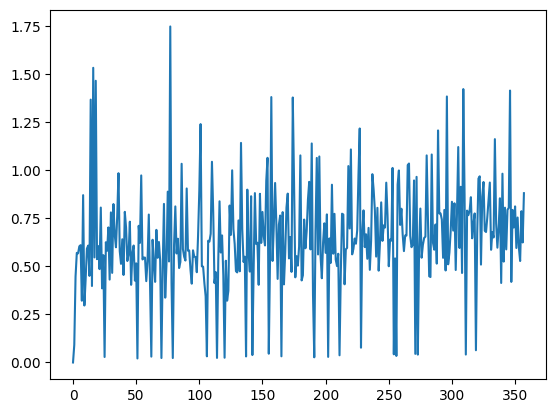

In [73]:
plt.plot(loss_all)
plt.show()

In [88]:
torch.tensor(loss_all)[:5000].mean()

tensor(4.0921)